Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Loading point cloud from: /home/t/Downloads/ger_normals.ply
Points: 2475311
Has normals: True
Has colors: True
Subsampling to 5000 points for visualization...
Saved visualization to 'point_cloud_with_normals.png'


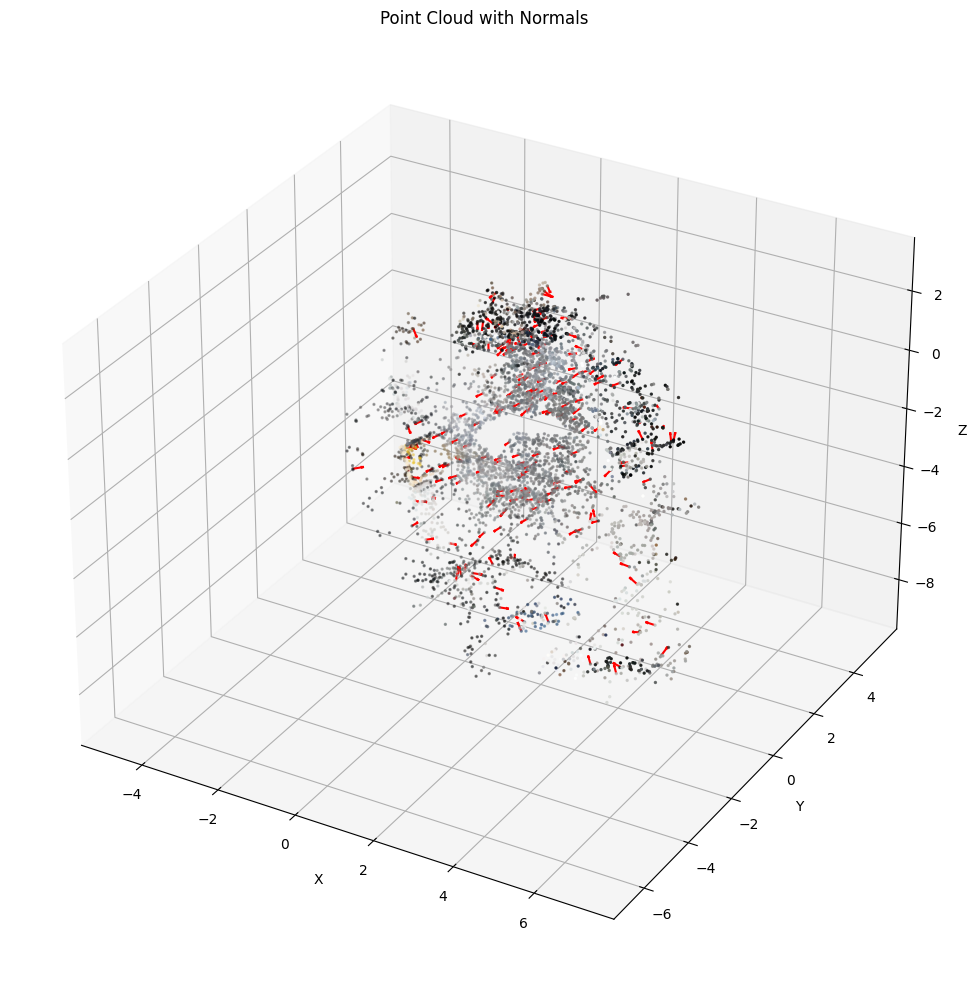

In [1]:
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def visualize_point_cloud_with_matplotlib(pcd_path, max_points=5000, normal_points=200):
    """
    Visualize a point cloud and its normals using Matplotlib
    
    Args:
        pcd_path (str): Path to the point cloud file
        max_points (int): Maximum number of points to display
        normal_points (int): Number of normal vectors to display
    """
    # Load the point cloud
    print(f"Loading point cloud from: {pcd_path}")
    pcd = o3d.io.read_point_cloud(pcd_path)
    
    # Print basic information
    print(f"Points: {len(pcd.points)}")
    print(f"Has normals: {pcd.has_normals()}")
    print(f"Has colors: {pcd.has_colors()}")
    
    # Convert to numpy arrays
    points = np.asarray(pcd.points)
    normals = np.asarray(pcd.normals) if pcd.has_normals() else None
    
    # Subsample for better visualization
    if len(points) > max_points:
        print(f"Subsampling to {max_points} points for visualization...")
        indices = np.random.choice(len(points), max_points, replace=False)
        points = points[indices]
        if normals is not None:
            normals = normals[indices]
        if pcd.has_colors():
            colors = np.asarray(pcd.colors)[indices]
    else:
        if pcd.has_colors():
            colors = np.asarray(pcd.colors)
    
    # Create a 3D plot
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # Plot the points
    if pcd.has_colors():
        # Convert colors from [0,1] to [0,255] if needed
        if colors.max() <= 1.0:
            colors = colors * 255
        ax.scatter(points[:, 0], points[:, 1], points[:, 2], 
                  c=colors/255, s=2)
    else:
        ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=2)
    
    # Plot a subset of normals as arrows
    if normals is not None:
        normal_indices = np.random.choice(len(points), min(normal_points, len(points)), replace=False)
        normal_scale = np.max([np.ptp(points[:, 0]), np.ptp(points[:, 1]), np.ptp(points[:, 2])]) * 0.02
        
        for i in normal_indices:
            ax.quiver(
                points[i, 0], points[i, 1], points[i, 2],
                normals[i, 0], normals[i, 1], normals[i, 2],
                length=normal_scale, color='red', arrow_length_ratio=0.3
            )
    
    # Set axis labels and title
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title('Point Cloud with Normals')
    
    # Set equal aspect ratio
    max_range = np.max([
        np.ptp(points[:, 0]), 
        np.ptp(points[:, 1]), 
        np.ptp(points[:, 2])
    ])
    mid_x = np.mean([np.min(points[:, 0]), np.max(points[:, 0])])
    mid_y = np.mean([np.min(points[:, 1]), np.max(points[:, 1])])
    mid_z = np.mean([np.min(points[:, 2]), np.max(points[:, 2])])
    ax.set_xlim(mid_x - max_range/2, mid_x + max_range/2)
    ax.set_ylim(mid_y - max_range/2, mid_y + max_range/2)
    ax.set_zlim(mid_z - max_range/2, mid_z + max_range/2)
    
    plt.tight_layout()
    plt.savefig('point_cloud_with_normals.png', dpi=300)
    print(f"Saved visualization to 'point_cloud_with_normals.png'")
    plt.show()

# Example usage
if __name__ == "__main__":
    pcd_path = "/home/t/Downloads/ger_normals.ply"
    visualize_point_cloud_with_matplotlib(pcd_path)

Points: 328102
Has normals: True
Has colors: True
Error reading PLY data: name 'file_path' is not defined

===== VISUALIZING DIFFRACTION MESH FILE =====
Loading /home/t/Desktop/3d_converge//results/saalas_mesh.ply...
File has edge data: False
Mesh has 328102 vertices and 368350 triangles
Starting visualization. Press Escape to exit.

===== BASIC POINT CLOUD VISUALIZATION =====

===== EXTRACTING DIFFRACTION EDGES =====

===== VISUALIZING POINT CLOUD WITH DIFFRACTION EDGES =====

===== DIFFRACTION EDGE ANALYSIS =====
Number of edges: 55
Total edge length: 253.29 units
Average edge length: 4.61 units
Minimum edge length: 0.82 units
Maximum edge length: 15.56 units


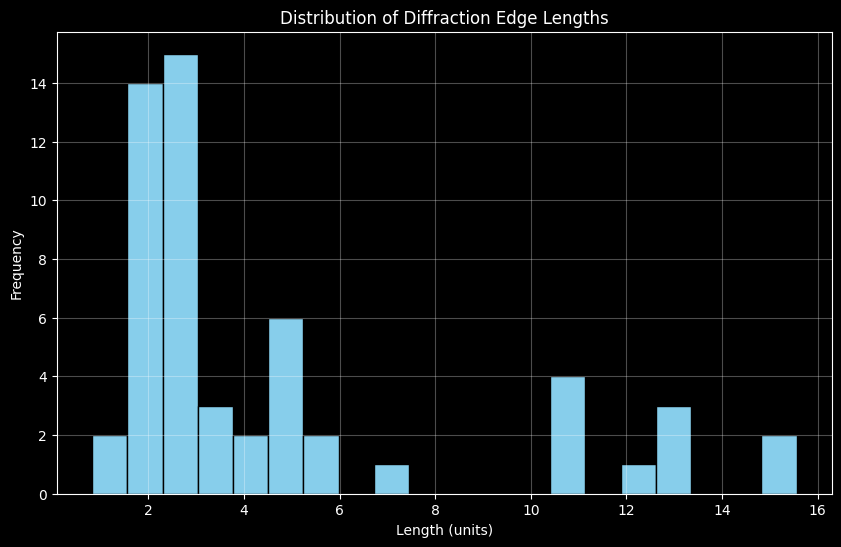

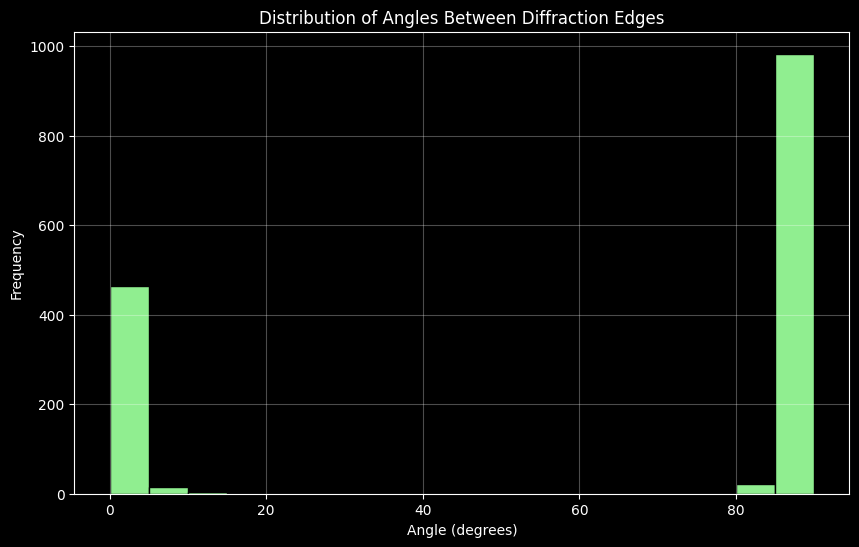


===== CREATING EDGE PROXIMITY HEATMAP =====


KeyboardInterrupt: 

In [2]:
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import RANSACRegressor
import pandas as pd
from scipy.spatial import cKDTree
import os
from matplotlib.colors import LinearSegmentedColormap
from plyfile import PlyData, PlyElement

# Set up notebook display options
plt.rcParams['figure.figsize'] = [12, 8]
plt.style.use('dark_background')

# ===== LOAD DATA =====
def load_point_cloud(file_path):
    """Load a point cloud and print basic information."""
    pcd = o3d.io.read_point_cloud(file_path)
    print(f"Points: {len(pcd.points)}")
    print(f"Has normals: {pcd.has_normals()}")
    print(f"Has colors: {pcd.has_colors()}")
    return pcd

# Load the segmented point cloud with diffraction edges
diffraction_file = "/home/t/Desktop/3d_converge/test_output/saalas_mesh.ply"
pcd = load_point_cloud(diffraction_file)

# ===== VISUALIZATION FUNCTIONS =====
def visualize_point_cloud(pcd, window_name="Point Cloud Visualization"):
    """Basic visualization of a point cloud."""
    vis = o3d.visualization.Visualizer()
    vis.create_window(window_name=window_name, width=1024, height=768)
    vis.add_geometry(pcd)
    
    # Set rendering options
    opt = vis.get_render_option()
    opt.background_color = np.array([0.1, 0.1, 0.1])  # Dark gray background
    opt.point_size = 2.0
    
    # Set initial viewpoint
    view_control = vis.get_view_control()
    view_control.set_zoom(0.8)
    
    # Run the visualizer
    vis.run()
    vis.destroy_window()

def extract_diffraction_edges(pcd, line_radius=0.02, color=[1, 0, 0]):
    """Extract and visualize diffraction edges from the mesh."""
    # ... existing code ...
    
    # Modify DBSCAN parameters to be more sensitive
    eps = 0.05  # Reduced from 0.1 to detect smaller clusters
    min_samples = 5  # Reduced from 10 to allow smaller edge segments
    
    # Modify the normal variation threshold
    threshold = np.percentile(normal_variations, 98)  # Top 2% instead of 5%
    
    # Add additional edge detection criteria
    if pcd.has_colors():
        colors = np.asarray(pcd.colors)
        # More lenient color thresholds
        edge_mask = (colors[:, 0] > 0.5) & (colors[:, 1] < 0.5) & (colors[:, 2] < 0.5)
        edge_points = points[edge_mask]
    
    # Modify clustering parameters
    clustering = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric='euclidean',
        algorithm='auto'
    ).fit(edge_points)
    
    # More lenient line fitting parameters
    def fit_line_to_cluster(cluster_points):
        if len(cluster_points) < min_samples:
            return None, None
            
        pca = PCA(n_components=3)
        pca.fit(cluster_points)
        
        # More lenient variance ratio thresholds
        if pca.explained_variance_ratio_[0] < 0.6:  # Was 0.8
            return None, None
        
        if pca.explained_variance_ratio_[1] > 0.2:  # Was 0.1
            return None, None
            
        # ... rest of the line fitting code ...
    
    # Add edge filtering based on angle between segments
    def filter_edges_by_angle(edges, min_angle=20):
        filtered_edges = []
        for i, edge1 in enumerate(edges):
            valid = True
            dir1 = edge1.points[1] - edge1.points[0]
            dir1 = dir1 / np.linalg.norm(dir1)
            
            for j, edge2 in enumerate(edges):
                if i != j:
                    dir2 = edge2.points[1] - edge2.points[0]
                    dir2 = dir2 / np.linalg.norm(dir2)
                    angle = np.arccos(np.abs(np.dot(dir1, dir2))) * 180 / np.pi
                    if angle < min_angle:
                        valid = False
                        break
            
            if valid:
                filtered_edges.append(edge1)
        
        return filtered_edges
    
    # Filter the edges
    edge_geometries = filter_edges_by_angle(edge_geometries)
    
    return edge_geometries
    
    # Create visualization geometries for each edge segment
    edge_geometries = []
    
    for segment in edge_segments:
        # Fit a line to the segment using PCA
        if len(segment) < 2:
            continue
            
        pca = PCA(n_components=3)
        pca.fit(segment)
        
        # Get the principal direction (first component)
        direction = pca.components_[0]
        
        # Project points onto the principal direction
        center = np.mean(segment, axis=0)
        projected = np.dot(segment - center, direction)
        
        # Find the extremes
        min_idx = np.argmin(projected)
        max_idx = np.argmax(projected)
        
        start_point = segment[min_idx]
        end_point = segment[max_idx]
        
        # Create a cylinder representing the edge
        cylinder = o3d.geometry.LineSet()
        cylinder.points = o3d.utility.Vector3dVector([start_point, end_point])
        cylinder.lines = o3d.utility.Vector2iVector([[0, 1]])
        cylinder.colors = o3d.utility.Vector3dVector([color])
        
        edge_geometries.append(cylinder)
    
    return edge_geometries

def visualize_diffraction_mesh_file(file_path):
    """
    Visualize a comprehensive PLY file created by the DiffractionEdgeDetector.
    Shows the 3D mesh as solid (not transparent), segmented planes, and diffraction edges.
    
    Args:
        file_path: Path to the PLY file created by diffraction.py
    """
    print(f"Loading {file_path}...")
    
    # Check if file exists
    if not os.path.exists(file_path):
        print(f"Error: File not found: {file_path}")
        return
    
    # Load the file as a mesh
    mesh = o3d.io.read_triangle_mesh(file_path)
    
    # Load the file for edge data
    try:
        ply_data = PlyData.read(file_path)
        has_edges = 'edge' in ply_data.elements
        print(f"File has edge data: {has_edges}")
    except Exception as e:
        print(f"Error reading PLY data: {e}")
        has_edges = False
    
    # Create visualization
    vis = o3d.visualization.Visualizer()
    vis.create_window(window_name="Diffraction Mesh Visualization", width=1024, height=768)
    
    # Add the mesh
    if mesh.has_vertex_colors():
        # Compute normals if they don't exist for proper lighting
        if not mesh.has_vertex_normals():
            mesh.compute_vertex_normals()
            
        print(f"Mesh has {len(mesh.vertices)} vertices and {len(mesh.triangles)} triangles")
        vis.add_geometry(mesh)
    else:
        print("Warning: Mesh has no vertex colors")
        
    # Extract and add edge geometries if edges exist
    if has_edges:
        edge_geometries = []
        for idx, edge in enumerate(ply_data['edge']):
            start_point = np.array([edge['start_x'], edge['start_y'], edge['start_z']])
            end_point = np.array([edge['end_x'], edge['end_y'], edge['end_z']])
            
            # Create a line set representing the edge
            line = o3d.geometry.LineSet()
            line.points = o3d.utility.Vector3dVector([start_point, end_point])
            line.lines = o3d.utility.Vector2iVector([[0, 1]])
            line.colors = o3d.utility.Vector3dVector([[1, 0, 0]])  # Red for edges
            
            edge_geometries.append(line)
            vis.add_geometry(line)
            
        print(f"Added {len(edge_geometries)} diffraction edges")
    
    # Set rendering options for solid rendering
    opt = vis.get_render_option()
    opt.background_color = np.array([0.1, 0.1, 0.1])  # Dark gray background
    opt.point_size = 2.0
    opt.line_width = 5.0  # Thicker lines for better edge visibility
    
    # Make mesh solid, not transparent
    opt.mesh_show_back_face = True  # Show back faces
    opt.mesh_show_wireframe = False  # Hide wireframe
    # Remove the line causing the error
    # opt.mesh_shade_option = o3d.visualization.MeshShadeOption.Flat  # Flat shading
    
    # Enable lighting for better 3D perception
    opt.light_on = True
    
    # Set initial viewpoint
    view_control = vis.get_view_control()
    view_control.set_zoom(0.8)
    
    # Run the visualizer
    print("Starting visualization. Press Escape to exit.")
    vis.run()
    vis.destroy_window()

def extract_edges_geometrically(pcd, line_radius=0.02, color=[1, 0, 0]):
    """
    Extract edges using geometric properties (intersections of planes).
    This is a simplified approach and may need refinement for specific datasets.
    """
    # Convert to numpy arrays
    points = np.asarray(pcd.points)
    
    # If normals are available, use them to identify potential edge points
    if pcd.has_normals():
        normals = np.asarray(pcd.normals)
        
        # Compute the variation of normals in local neighborhoods
        tree = cKDTree(points)
        k = 30  # Number of neighbors to consider
        
        # For each point, compute normal variation in its neighborhood
        normal_variations = []
        for i in range(len(points)):
            # Find k nearest neighbors
            distances, indices = tree.query(points[i], k=min(k, len(points)))
            
            # Get normals of neighbors
            neighbor_normals = normals[indices]
            
            # Compute the average normal
            avg_normal = np.mean(neighbor_normals, axis=0)
            avg_normal = avg_normal / np.linalg.norm(avg_normal)
            
            # Compute variation as the average angular deviation
            dot_products = np.abs(np.dot(neighbor_normals, avg_normal))
            variation = 1.0 - np.mean(dot_products)
            
            normal_variations.append(variation)
        
        normal_variations = np.array(normal_variations)
        
        # Threshold to identify edge points (high normal variation)
        threshold = np.percentile(normal_variations, 95)  # Top 5% of variations
        edge_mask = normal_variations > threshold
        edge_points = points[edge_mask]
        
        print(f"Found {len(edge_points)} potential edge points based on normal variation")
    else:
        print("Point cloud has no normals. Cannot extract edges geometrically.")
        return []
    
    # Cluster edge points to find separate edges
    # Use DBSCAN for clustering
    from sklearn.cluster import DBSCAN
    
    # Parameters for DBSCAN
    eps = 0.1  # Maximum distance between points in a cluster
    min_samples = 10  # Minimum number of points to form a cluster
    
    # Apply DBSCAN
    clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(edge_points)
    labels = clustering.labels_
    
    # Number of clusters (excluding noise with label -1)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"Found {n_clusters} edge clusters")
    
    # Create visualization geometries for each edge cluster
    edge_geometries = []
    
    for i in range(n_clusters):
        # Get points in this cluster
        cluster_points = edge_points[labels == i]
        
        # Fit a line to the cluster using PCA
        if len(cluster_points) < 2:
            continue
            
        pca = PCA(n_components=3)
        pca.fit(cluster_points)
        
        # Get the principal direction (first component)
        direction = pca.components_[0]
        
        # Project points onto the principal direction
        center = np.mean(cluster_points, axis=0)
        projected = np.dot(cluster_points - center, direction)
        
        # Find the extremes
        min_idx = np.argmin(projected)
        max_idx = np.argmax(projected)
        
        start_point = cluster_points[min_idx]
        end_point = cluster_points[max_idx]
        
        # Create a line set representing the edge
        line = o3d.geometry.LineSet()
        line.points = o3d.utility.Vector3dVector([start_point, end_point])
        line.lines = o3d.utility.Vector2iVector([[0, 1]])
        line.colors = o3d.utility.Vector3dVector([color])
        
        edge_geometries.append(line)
    
    return edge_geometries

def visualize_with_diffraction_edges(pcd, edge_geometries=None):
    """
    Visualize the point cloud with highlighted diffraction edges.
    
    Args:
        pcd: Original point cloud
        edge_geometries: List of geometries representing edges (optional)
    """
    # If edge geometries not provided, extract them
    if edge_geometries is None:
        edge_geometries = extract_diffraction_edges(pcd)
    
    # Create a visualization window
    vis = o3d.visualization.Visualizer()
    vis.create_window(window_name="Point Cloud with Diffraction Edges", width=1024, height=768)
    
    # Add the original point cloud
    vis.add_geometry(pcd)
    
    # Add each edge geometry
    for edge in edge_geometries:
        vis.add_geometry(edge)
    
    # Set rendering options
    opt = vis.get_render_option()
    opt.background_color = np.array([0.1, 0.1, 0.1])  # Dark gray background
    opt.point_size = 1.0  # Smaller points to better see the edges
    
    # Set initial viewpoint
    view_control = vis.get_view_control()
    view_control.set_zoom(0.8)
    
    # Run the visualizer
    vis.run()
    vis.destroy_window()
    
def extract_diffraction_edges_from_mesh(pcd):
    """Extract edges using the same logic as the main pipeline."""
    from diffraction import DiffractionEdgeDetector
    
    # Create detector with the same parameters as the pipeline
    detector = DiffractionEdgeDetector(
        min_points=20,
        ransac_threshold=0.1,
        distance_threshold=0.15
    )
    
    # Process the point cloud
    detector.extract_planes_from_segmented_pcd(pcd)
    detector.find_diffraction_edges()
    
    # Convert diffraction edges to visualization geometries
    edge_geometries = []
    for (start_point, end_point), _, _, _ in detector.diffraction_edges:
        line = o3d.geometry.LineSet()
        line.points = o3d.utility.Vector3dVector([start_point, end_point])
        line.lines = o3d.utility.Vector2iVector([[0, 1]])
        line.colors = o3d.utility.Vector3dVector([[1, 0, 0]])
        edge_geometries.append(line)
    
    return edge_geometries

def analyze_diffraction_edges(pcd, edge_geometries):
    """
    Analyze properties of the detected diffraction edges.
    
    Args:
        pcd: Original point cloud
        edge_geometries: List of geometries representing edges
    """
    # Extract edge information
    edge_data = []
    
    for i, edge in enumerate(edge_geometries):
        # Get start and end points
        points = np.asarray(edge.points)
        if len(points) < 2:
            continue
            
        start_point = points[0]
        end_point = points[1]
        
        # Calculate edge length
        length = np.linalg.norm(end_point - start_point)
        
        # Calculate edge direction
        direction = (end_point - start_point) / length
        
        # Store data
        edge_data.append({
            'Edge ID': i,
            'Start Point': start_point,
            'End Point': end_point,
            'Length': length,
            'Direction': direction
        })
    
    # Create a DataFrame for analysis
    if edge_data:
        df = pd.DataFrame(edge_data)
        
        # Print summary statistics
        print("\n===== DIFFRACTION EDGE ANALYSIS =====")
        print(f"Number of edges: {len(df)}")
        print(f"Total edge length: {df['Length'].sum():.2f} units")
        print(f"Average edge length: {df['Length'].mean():.2f} units")
        print(f"Minimum edge length: {df['Length'].min():.2f} units")
        print(f"Maximum edge length: {df['Length'].max():.2f} units")
        
        # Plot edge length distribution
        plt.figure(figsize=(10, 6))
        plt.hist(df['Length'], bins=20, color='skyblue', edgecolor='black')
        plt.title('Distribution of Diffraction Edge Lengths')
        plt.xlabel('Length (units)')
        plt.ylabel('Frequency')
        plt.grid(alpha=0.3)
        plt.show()
        
        # Analyze edge directions
        directions = np.vstack(df['Direction'].values)
        
        # Compute pairwise angles between edges
        angles = []
        for i in range(len(directions)):
            for j in range(i+1, len(directions)):
                dot_product = np.abs(np.dot(directions[i], directions[j]))
                angle = np.arccos(min(dot_product, 1.0)) * 180 / np.pi
                angles.append(angle)
        
        if angles:
            plt.figure(figsize=(10, 6))
            plt.hist(angles, bins=18, color='lightgreen', edgecolor='black')
            plt.title('Distribution of Angles Between Diffraction Edges')
            plt.xlabel('Angle (degrees)')
            plt.ylabel('Frequency')
            plt.grid(alpha=0.3)
            plt.show()
        
        return df
    else:
        print("No edge data available for analysis.")
        return None
    
# Load the file for edge data
try:
    ply_data = PlyData.read(file_path)
    # Check specifically for 'edge' element
    has_edges = False
    for element in ply_data.elements:
        if element.name == 'edge':
            has_edges = True
            print(f"Found {len(element.data)} diffraction edges in the file")
            break
except Exception as e:
    print(f"Error reading PLY data: {e}")
    has_edges = False

# ===== MAIN EXECUTION =====



print("\n===== VISUALIZING DIFFRACTION MESH FILE =====")
# Update this path to your file created by diffraction.py
diffraction_mesh_file = "/home/t/Desktop/3d_converge/test_output/saalas_mesh.ply"
visualize_diffraction_mesh_file(diffraction_mesh_file)


# 1. Basic visualization of the point cloud
print("\n===== BASIC POINT CLOUD VISUALIZATION =====")
visualize_point_cloud(pcd)

# 2. Extract and visualize diffraction edges
print("\n===== EXTRACTING DIFFRACTION EDGES =====")
edge_geometries = extract_diffraction_edges_from_mesh(pcd)

# 3. Visualize point cloud with highlighted diffraction edges
print("\n===== VISUALIZING POINT CLOUD WITH DIFFRACTION EDGES =====")
visualize_with_diffraction_edges(pcd, edge_geometries)

# 4. Analyze properties of the diffraction edges
edge_df = analyze_diffraction_edges(pcd, edge_geometries)

# 5. Advanced visualization: Create a heatmap of edge proximity
print("\n===== CREATING EDGE PROXIMITY HEATMAP =====")

# Convert to numpy for processing
points = np.asarray(pcd.points)

# Create a copy of the point cloud for the heatmap
heatmap_pcd = o3d.geometry.PointCloud()
heatmap_pcd.points = o3d.utility.Vector3dVector(points)

# Calculate distance from each point to the nearest edge
min_distances = np.ones(len(points)) * float('inf')

for edge in edge_geometries:
    edge_points = np.asarray(edge.points)
    if len(edge_points) < 2:
        continue
        
    start = edge_points[0]
    end = edge_points[1]
    
    # Calculate distances from points to this line segment
    for i, point in enumerate(points):
        # Vector from start to point
        v = point - start
        # Vector from start to end
        w = end - start
        
        # Length of the line segment
        length = np.linalg.norm(w)
        
        # Normalize w
        w_normalized = w / length
        
        # Project v onto w
        proj = np.dot(v, w_normalized)
        
        # Calculate the closest point on the line segment
        if proj < 0:
            closest = start
        elif proj > length:
            closest = end
        else:
            closest = start + proj * w_normalized
        
        # Calculate distance
        distance = np.linalg.norm(point - closest)
        
        # Update minimum distance
        min_distances[i] = min(min_distances[i], distance)

# Normalize distances for coloring
max_dist = np.max(min_distances)
normalized_distances = min_distances / max_dist

# Create a custom colormap: blue (far) to red (close)
colors = np.zeros((len(points), 3))
for i in range(len(points)):
    # Reversed: 1.0 - normalized_distances[i] so red is close to edges
    t = 1.0 - normalized_distances[i]
    # Blue (far) to Red (close)
    colors[i] = [t, 0, 1-t]

heatmap_pcd.colors = o3d.utility.Vector3dVector(colors)

# Visualize the heatmap
print("Visualizing proximity heatmap (red = close to edges, blue = far from edges)")
visualize_point_cloud(heatmap_pcd, "Edge Proximity Heatmap")

print("\nAnalysis complete!")